# Model I
## Rozpoznawanie instrumentów za pomocą sieci CNN
### Bilbioteki

In [1]:
from datetime import datetime
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import f1_score
import time
from model import InstrumentCNN
from trening import get_device, train_model
from przygotowanie_danych import (
    INSTRUMENTS,
    create_datasets,
    create_loaders
)

In [33]:
# Konfiguracja eksperymentu
epochs = 100
patience = 10
batch_size =32
learning_rate = 0.0008

dropout2 = 0.1
dropout3 = 0.3

threshold = 0.8

# Unikalna nazwa pliku z wagami
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
expression_id = f"CNN1_{timestamp}"
weights_filename = f"weights_{expression_id}.pth"

# Parametry spektrogramów 
spectrograms_parameters_desc = 'mels128_frame4096_step1024_windowhann_sr44100_4s'

# Zapis parametrów w słowniku
experiment = {
    "Experiment_ID": expression_id,
    "Model": "CNN1",
    "Spectrogram_Params": spectrograms_parameters_desc,
    "Batch_size": batch_size,
    "Learning_rate": learning_rate,
    "Dropout_2": dropout2,
    "Dropout_3": dropout3,
    "Threshold": threshold
}

print(f"Rozpoczęto eksperyment: {expression_id}")

Rozpoczęto eksperyment: CNN1_20261114_140751


In [34]:
train_dataset, val_dataset, test_dataset = create_datasets()

train_loader, val_loader, test_loader = create_loaders(train_dataset, val_dataset, test_dataset, batch_size=batch_size)

In [35]:
device = get_device()

model = InstrumentCNN(dropout2=dropout2, dropout3=dropout3).to(device)
criterion = nn.MultiLabelSoftMarginLoss()
optimizer = optim.Adam(model.parameters(),lr=learning_rate)

print(device)

cuda


## Trening modelu

Do uczenia sieci wykorzystano standardowy optymalizator Adam. Zastosowano także mechanizm *Early stopping*, który zatrzymuje trening w przypadku braku 

In [36]:
start_time = time.perf_counter()
model, history, best_epoch, best_val_loss = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=epochs,
    patience=patience,
    model_name=weights_filename
)
training_time = time.perf_counter() - start_time

print(f"Czas treningu: {training_time / 60:.2f} min")

Epoka 1/100 | Train loss: 0.6676 | Val loss: 0.5916
Epoka 2/100 | Train loss: 0.5779 | Val loss: 0.5353
Epoka 3/100 | Train loss: 0.5467 | Val loss: 0.5206
Epoka 4/100 | Train loss: 0.5313 | Val loss: 0.5032
Epoka 5/100 | Train loss: 0.5136 | Val loss: 0.4942
Epoka 6/100 | Train loss: 0.5021 | Val loss: 0.4683
Epoka 7/100 | Train loss: 0.4884 | Val loss: 0.4551
Epoka 8/100 | Train loss: 0.4787 | Val loss: 0.4396
Epoka 9/100 | Train loss: 0.4669 | Val loss: 0.4420
Epoka 10/100 | Train loss: 0.4588 | Val loss: 0.4181
Epoka 11/100 | Train loss: 0.4456 | Val loss: 0.4164
Epoka 12/100 | Train loss: 0.4393 | Val loss: 0.4016
Epoka 13/100 | Train loss: 0.4291 | Val loss: 0.3979
Epoka 14/100 | Train loss: 0.4212 | Val loss: 0.3850
Epoka 15/100 | Train loss: 0.4160 | Val loss: 0.3783
Epoka 16/100 | Train loss: 0.4090 | Val loss: 0.3628
Epoka 17/100 | Train loss: 0.4013 | Val loss: 0.3634
Epoka 18/100 | Train loss: 0.3970 | Val loss: 0.3566
Epoka 19/100 | Train loss: 0.3885 | Val loss: 0.3586
Ep

In [37]:
instrument_names = list(INSTRUMENTS.values())

model.eval()

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)

        logits = model(X)
        probabilities = torch.sigmoid(logits).cpu().numpy()
        predictions = (probabilities >= threshold).astype(int)
        true_labels = y.cpu().numpy().astype(int)

        print("Prawdopodobieństwa:")
        display(pd.DataFrame(probabilities, columns=instrument_names).round(3))
        
        print("Przewidywane etykiety:")
        display(pd.DataFrame(predictions, columns=instrument_names))
        
        print("Prawdziwe etykiety:")
        display(pd.DataFrame(true_labels, columns=instrument_names))

        break

Prawdopodobieństwa:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,0.963,0.568,0.915,1.000,1.000,0.617,0.919
1,0.604,0.578,0.991,1.000,0.015,0.192,0.069
2,0.040,0.999,0.001,1.000,0.005,0.912,0.023
3,0.114,0.454,0.451,1.000,0.009,0.371,0.946
4,0.963,0.227,0.677,1.000,0.907,0.877,0.090
5,1.000,0.431,0.049,0.000,0.020,0.064,0.999
6,0.070,0.117,0.994,0.000,1.000,0.214,0.391
7,0.163,0.874,0.922,1.000,0.001,0.885,0.921
8,1.000,0.746,0.150,0.000,0.009,0.049,0.998
9,0.768,0.915,0.452,0.000,0.999,0.277,0.971


Przewidywane etykiety:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,1,0,1,1,1,0,1
1,0,0,1,1,0,0,0
2,0,1,0,1,0,1,0
3,0,0,0,1,0,0,1
4,1,0,0,1,1,1,0
5,1,0,0,0,0,0,1
6,0,0,1,0,1,0,0
7,0,1,1,1,0,1,1
8,1,0,0,0,0,0,1
9,0,1,0,0,1,0,1


Prawdziwe etykiety:


,Gitara akustyczna,Saksofon altowy,Fortepian,Perkusja,Gitara basowa,Flet,Sekcja smyczkowa
0,1,0,1,1,1,1,1
1,0,1,1,1,0,0,0
2,0,1,0,1,0,1,0
3,0,1,0,1,0,0,1
4,1,0,1,1,1,1,0
5,1,0,0,0,0,0,1
6,0,0,1,0,1,0,1
7,0,1,1,1,0,1,1
8,1,1,0,0,0,0,1
9,1,1,0,0,1,0,1


In [38]:
model.eval()

all_predictions = []
all_labels = []
val_loss = 0.0

with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)
        y = y.to(device)

        logits = model(X)
        loss = criterion(logits, y)

        val_loss += loss.item() * X.size(0)

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= threshold).float()

        all_predictions.append(predictions.cpu().numpy())
        all_labels.append(y.cpu().numpy())

val_loss /= len(val_loader.dataset)

all_predictions = np.concatenate(all_predictions, axis=0)
all_labels = np.concatenate(all_labels, axis=0)

f1_micro = f1_score(all_labels, all_predictions, average="micro", zero_division=0)
f1_macro = f1_score(all_labels, all_predictions, average="macro", zero_division=0)
f1_per_instrument = f1_score(all_labels, all_predictions, average=None, zero_division=0)

print(f"Validation loss: {val_loss:.4f}")
print(f"Micro-F1: {f1_micro:.4f}")
print(f"Macro-F1: {f1_macro:.4f}")

results = pd.DataFrame({
    "Instrument": list(INSTRUMENTS.values()),
    "F1-score": f1_per_instrument
})

display(results.round(4))

Validation loss: 0.2106
Micro-F1: 0.8414
Macro-F1: 0.8204


,Instrument,F1-score
0,Gitara akustyczna,0.8269
1,Saksofon altowy,0.7224
2,Fortepian,0.7525
3,Perkusja,0.9976
4,Gitara basowa,0.9543
5,Flet,0.5927
6,Sekcja smyczkowa,0.8963


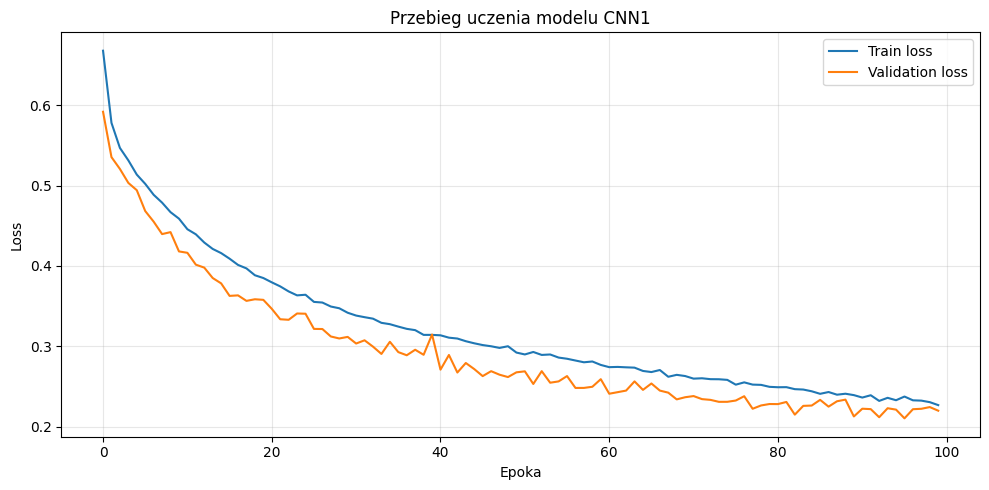

In [39]:
plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Train loss")
plt.plot(history["val_loss"], label="Validation loss")

plt.xlabel("Epoka")
plt.ylabel("Loss")
plt.title("Przebieg uczenia modelu CNN1")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

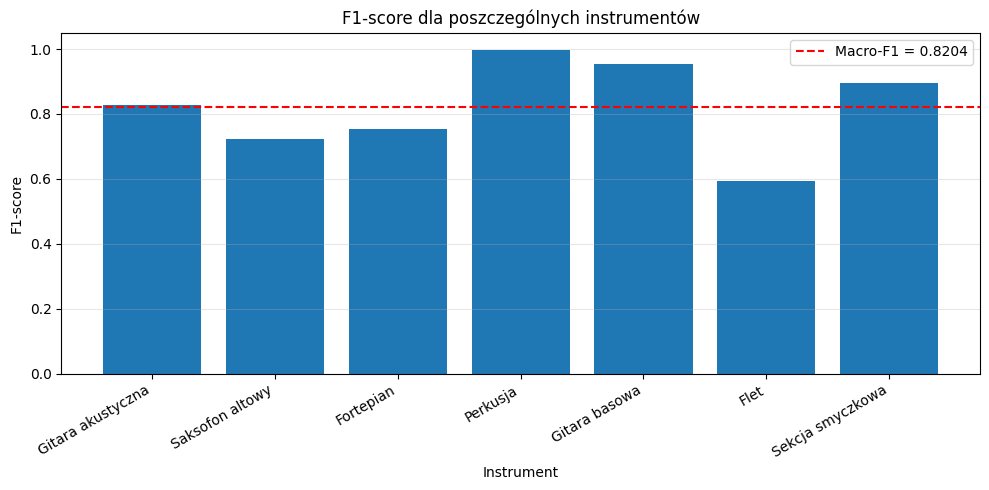

In [40]:
plt.figure(figsize=(10, 5))

plt.bar(results["Instrument"], results["F1-score"])

plt.axhline(
    y=f1_macro,
    color="red",
    linestyle="--",
    label=f"Macro-F1 = {f1_macro:.4f}"
)

plt.xlabel("Instrument")
plt.ylabel("F1-score")
plt.title("F1-score dla poszczególnych instrumentów")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [41]:
from sklearn.metrics import precision_score, recall_score

precision = precision_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average=None,
    zero_division=0
)

metrics = pd.DataFrame({
    "Instrument": list(INSTRUMENTS.values()),
    "Precision": precision,
    "Recall": recall
})

display(metrics.round(4))

,Instrument,Precision,Recall
0,Gitara akustyczna,0.9930,0.7084
1,Saksofon altowy,0.9598,0.5792
2,Fortepian,0.9798,0.6108
3,Perkusja,1.0000,0.9952
4,Gitara basowa,0.9858,0.9248
5,Flet,0.9708,0.4265
6,Sekcja smyczkowa,0.9970,0.8141


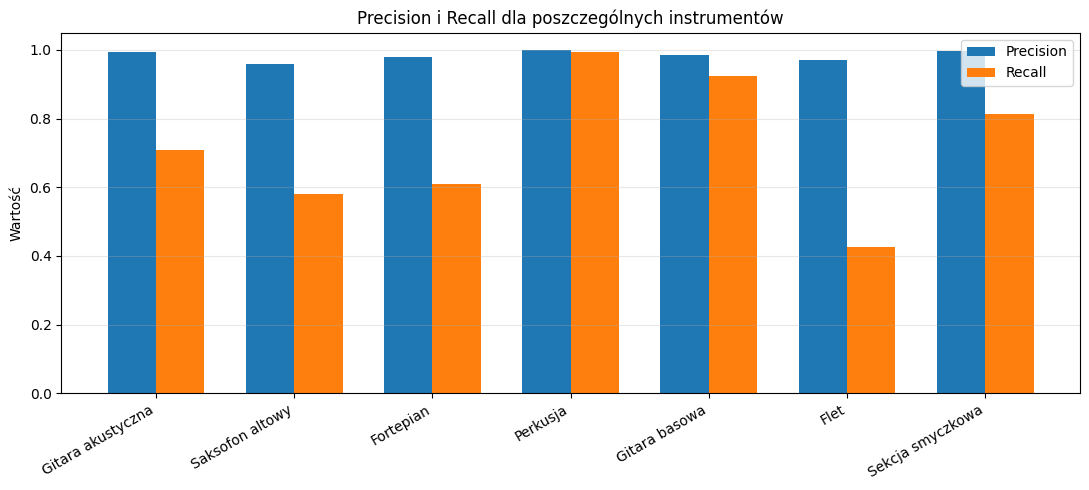

In [42]:
x = np.arange(len(INSTRUMENTS))
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(x - width / 2, precision, width, label="Precision")
plt.bar(x + width / 2, recall, width, label="Recall")

plt.xticks(x, list(INSTRUMENTS.values()), rotation=30, ha="right")
plt.ylabel("Wartość")
plt.title("Precision i Recall dla poszczególnych instrumentów")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [43]:
# Zapis wyników treningu do csv

results_dir = Path("wyniki")
results_dir.mkdir(exist_ok=True)

results_file = results_dir / "porownanie_eksperymentow_v2.csv"

experiment.update({
    "Best_epoch": best_epoch,
    "Best_val_loss": best_val_loss,
    "Micro-F1": f1_micro,
    "Macro-F1": f1_macro,
    "Weights_file": weights_filename
})

experiment_summary = pd.DataFrame([experiment])

if results_file.exists():
    experiment_summary.to_csv(results_file, mode="a", header=False, index=False)
else:
    experiment_summary.to_csv(results_file, index=False)

print(f"Wyniki eksperymentu zapisano w {results_file}.")

Wyniki eksperymentu zapisano w wyniki\porownanie_eksperymentow_v2.csv.


In [44]:
comparison = pd.read_csv(results_file)
display(comparison.round(4))

,Experiment_ID,Model,Spectrogram_Params,Batch_size,Learning_rate,Dropout_2,Dropout_3,Threshold,Best_epoch,Best_val_loss,Micro-F1,Macro-F1,Weights_file
0,CNN1_20261114_101436,CNN1,mels128_frame2048_step512_windowhann_sr44100_4s,32,0.0005,0.1,0.3,0.8,98,0.2147,0.8409,0.8183,weights_CNN1_20261114_101436.pth
1,CNN1_20261114_110608,CNN1,mels128_frame2048_step1024_windowhann_sr44100_4s,32,0.0005,0.1,0.3,0.8,98,0.2122,0.8414,0.8158,weights_CNN1_20261114_110608.pth
2,CNN1_20261114_140751,CNN1,mels128_frame4096_step1024_windowhann_sr44100_4s,32,0.0008,0.1,0.3,0.8,96,0.2106,0.8414,0.8204,weights_CNN1_20261114_140751.pth
